# 10 — Ablation Study and Explainability
Every ablation retrains the selected MAF-Net configuration with three seeds; metrics are reported
on validation (selection-relevant) and test (held-out).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:07 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
ab = pd.read_csv(ROOT / "results/tables/ablation.csv")
ab.sort_values("val_macro_f1", ascending=False).round(4)

,variant,modalities,n_params,val_macro_f1,val_macro_f1_std,macro_f1,macro_f1_std,balanced_accuracy,accuracy,roc_auc_macro_ovr,pr_auc_macro
7,all_attention,C+A+D+ctx,33268,0.7429,0.0025,0.7426,0.0010,0.7482,0.8075,0.9412,0.7857
10,with_transferred_drought_features,C+A+D+ctx+TL,33508,0.7411,0.0026,0.7400,0.0039,0.7430,0.8057,0.9404,0.7834
5,all_concat_no_attention,C+A+D+ctx,21652,0.7397,0.0024,0.7396,0.0029,0.7482,0.8016,0.9391,0.7795
6,all_attention_no_context,C+A+D,32484,0.7391,0.0010,0.7350,0.0057,0.7463,0.8014,0.9391,0.7747
9,with_modality_dropout,C+A+D+ctx,33268,0.7380,0.0025,0.7381,0.0034,0.7426,0.8031,0.9396,0.7805
8,no_humidity,C+A+D+ctx −humidity,32980,0.7314,0.0010,0.7072,0.0163,0.7253,0.7742,0.9277,0.7470
3,climate_air,C+A+ctx,31284,0.7304,0.0019,0.7231,0.0017,0.7283,0.7910,0.9312,0.7584
4,climate_dryness,C+D+ctx,31284,0.6890,0.0164,0.6546,0.0337,0.6789,0.7493,0.9049,0.7045
0,climate_only,C,28516,0.6381,0.0089,0.6292,0.0059,0.6349,0.7286,0.8755,0.6543
2,dryness_only,D,18116,0.6132,0.0029,0.5534,0.0025,0.5899,0.6548,0.8247,0.5717


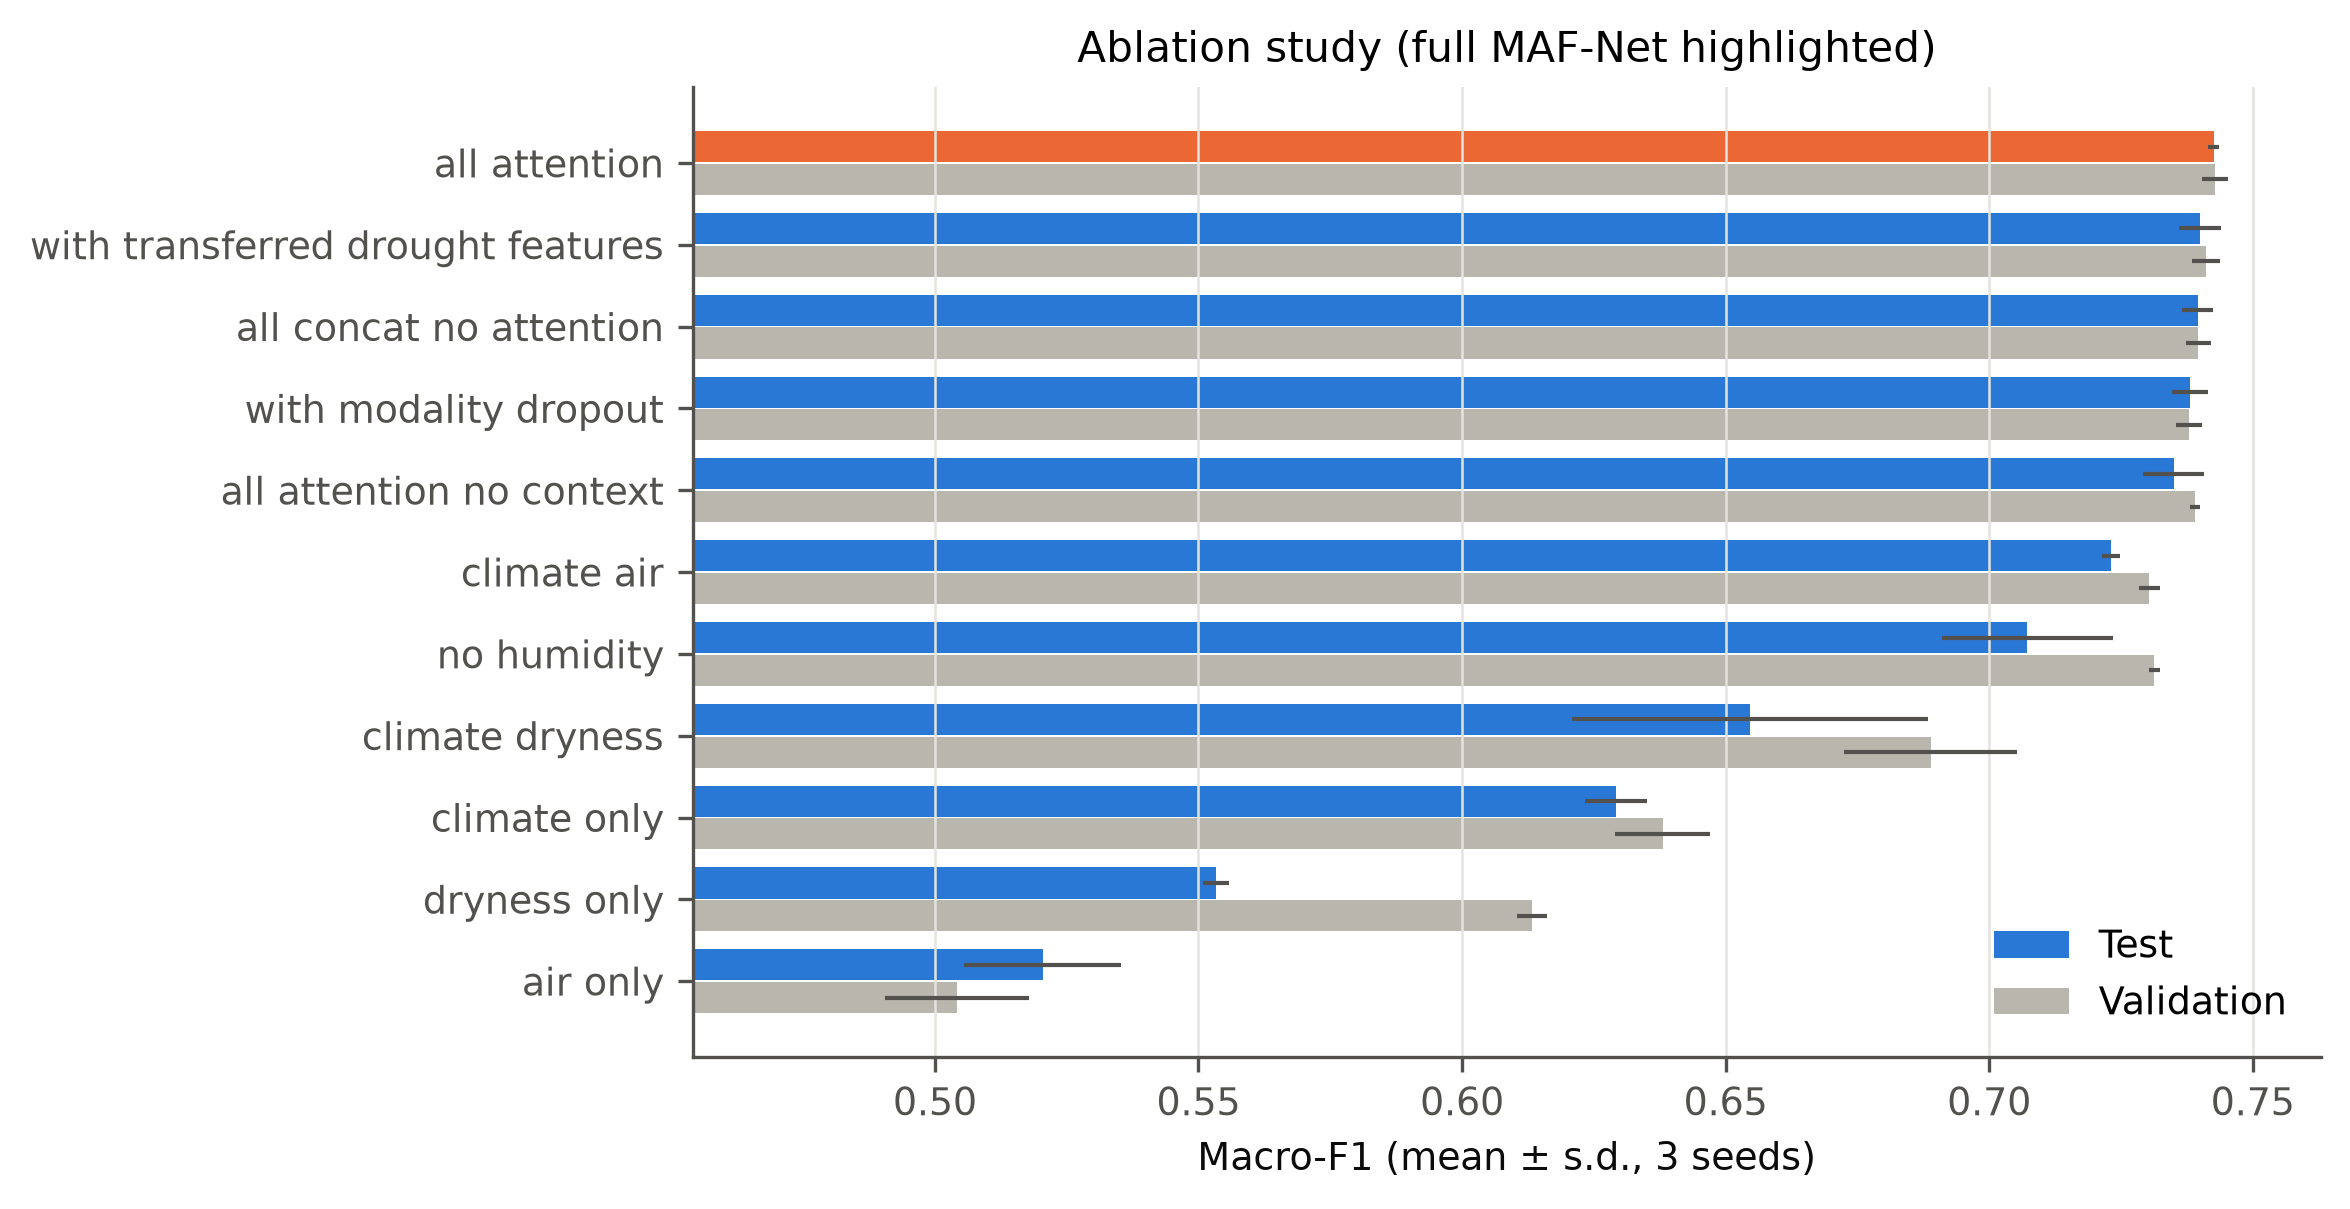

In [3]:
show("results/figures/ablation.png", 700)

### Look-back length (validation; each length has its own sample set)

In [4]:
pd.read_csv(ROOT / "results/tables/lookback.csv")[["lookback","n_runs","val_macro_f1","val_macro_f1_std","macro_f1","macro_f1_std"]].round(4)

,lookback,n_runs,val_macro_f1,val_macro_f1_std,macro_f1,macro_f1_std
0,7,3,0.7407,0.0018,0.7338,0.0041
1,14,3,0.7429,0.0025,0.7426,0.0010
2,30,3,0.7388,0.0022,0.7356,0.0024


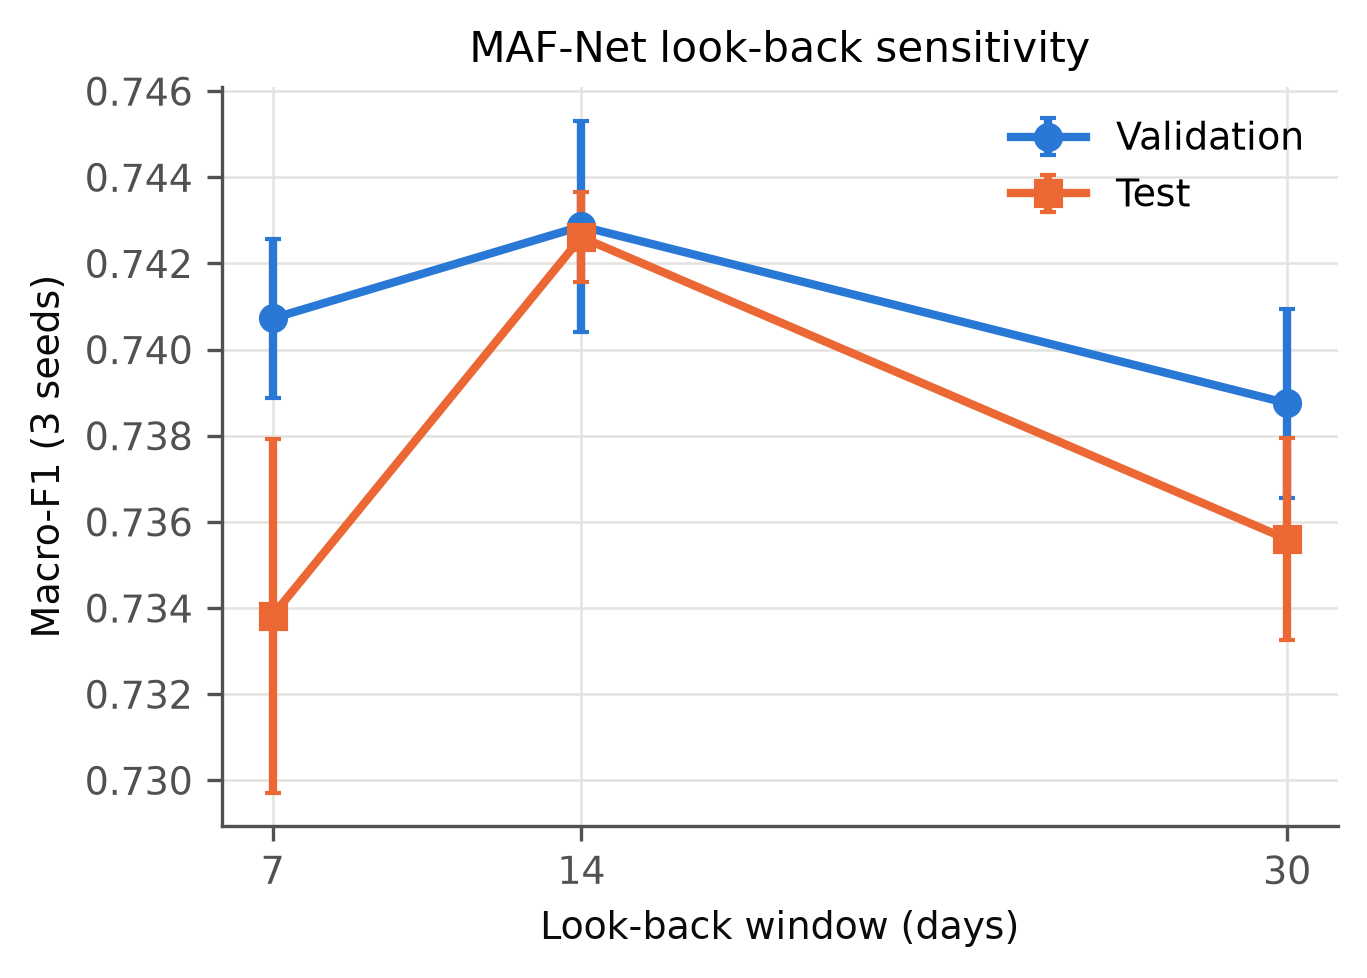

In [5]:
show("results/figures/lookback.png", 450)

### Transferred drought representation (auxiliary US benchmark)

US drought benchmark (400 counties, 30-day weather → USDM class)
  test macro-F1 = 0.348 (majority = 0.213), balanced acc = 0.509
  transfer features on capital-city sites: {'rows_with_features': 156543, 'mean_severity': 1.747701357814815, 'share_argmax_ge_D2': 0.5031141603265556}


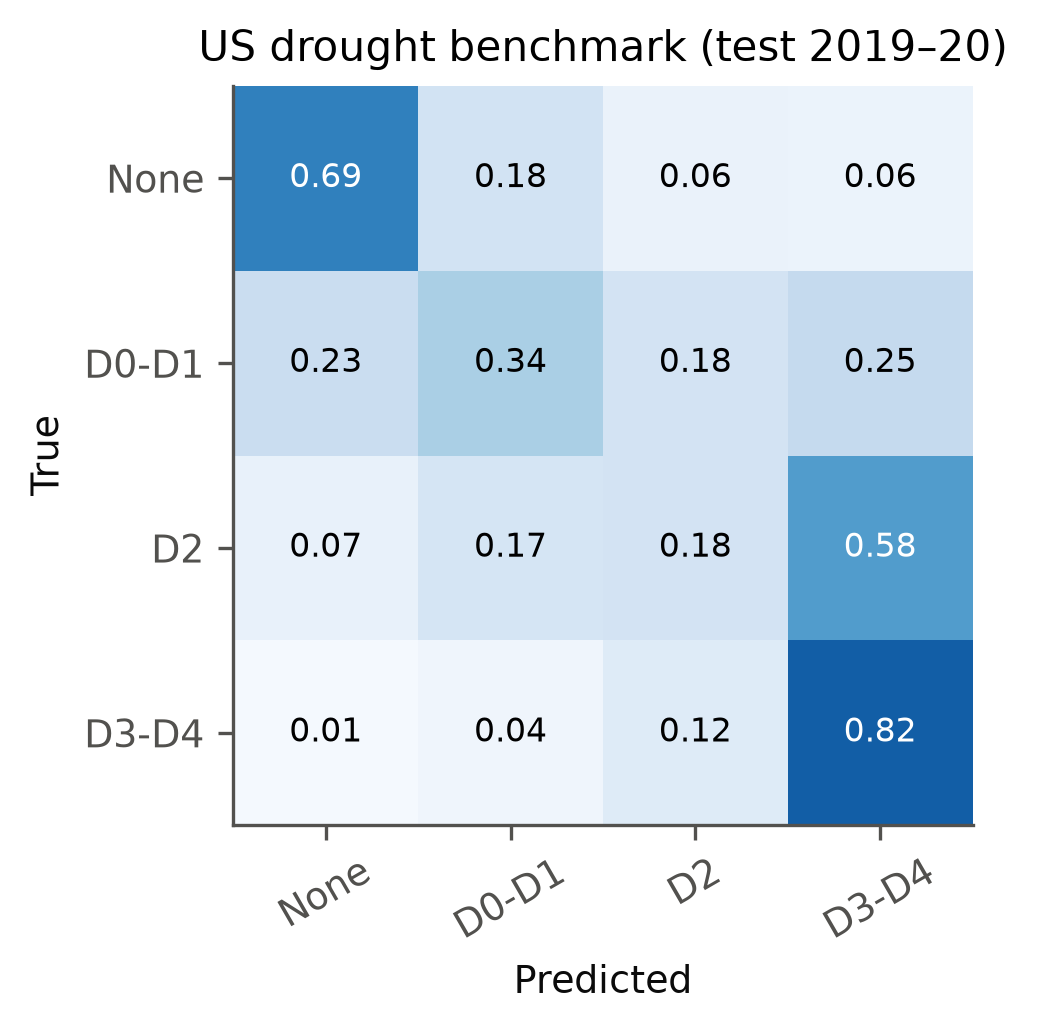

In [6]:
dr = read_json(ROOT / "experiments/drought_aux/drought_aux_results.json")
print("US drought benchmark (400 counties, 30-day weather → USDM class)")
print("  test macro-F1 = %.3f (majority = %.3f), balanced acc = %.3f" % (dr["test_metrics"]["macro_f1"], dr["test_majority_macro_f1"], dr["test_metrics"]["balanced_accuracy"]))
print("  transfer features on capital-city sites:", dr["transfer_feature_summary"])
show("results/figures/drought_aux_confusion.png", 380)

### Explainability
* **Permutation importance** — drop in macro-F1 when a feature's whole 14-day trajectory is
  shuffled across samples (test subset of 8 000 windows).
* **Integrated gradients** (32 steps, zero baseline = training mean) for samples predicted High/Critical.
* **Attention weights** by predicted class. Attention is descriptive, not causal.

,mean_drop_macro_f1,std
Climate (all),0.1995,0.0006
Air quality (all),0.1480,0.0021
Dryness proxy (all),0.2378,0.0032
Humidity-derived,0.3960,0.0029
Static context,0.0073,0.0000


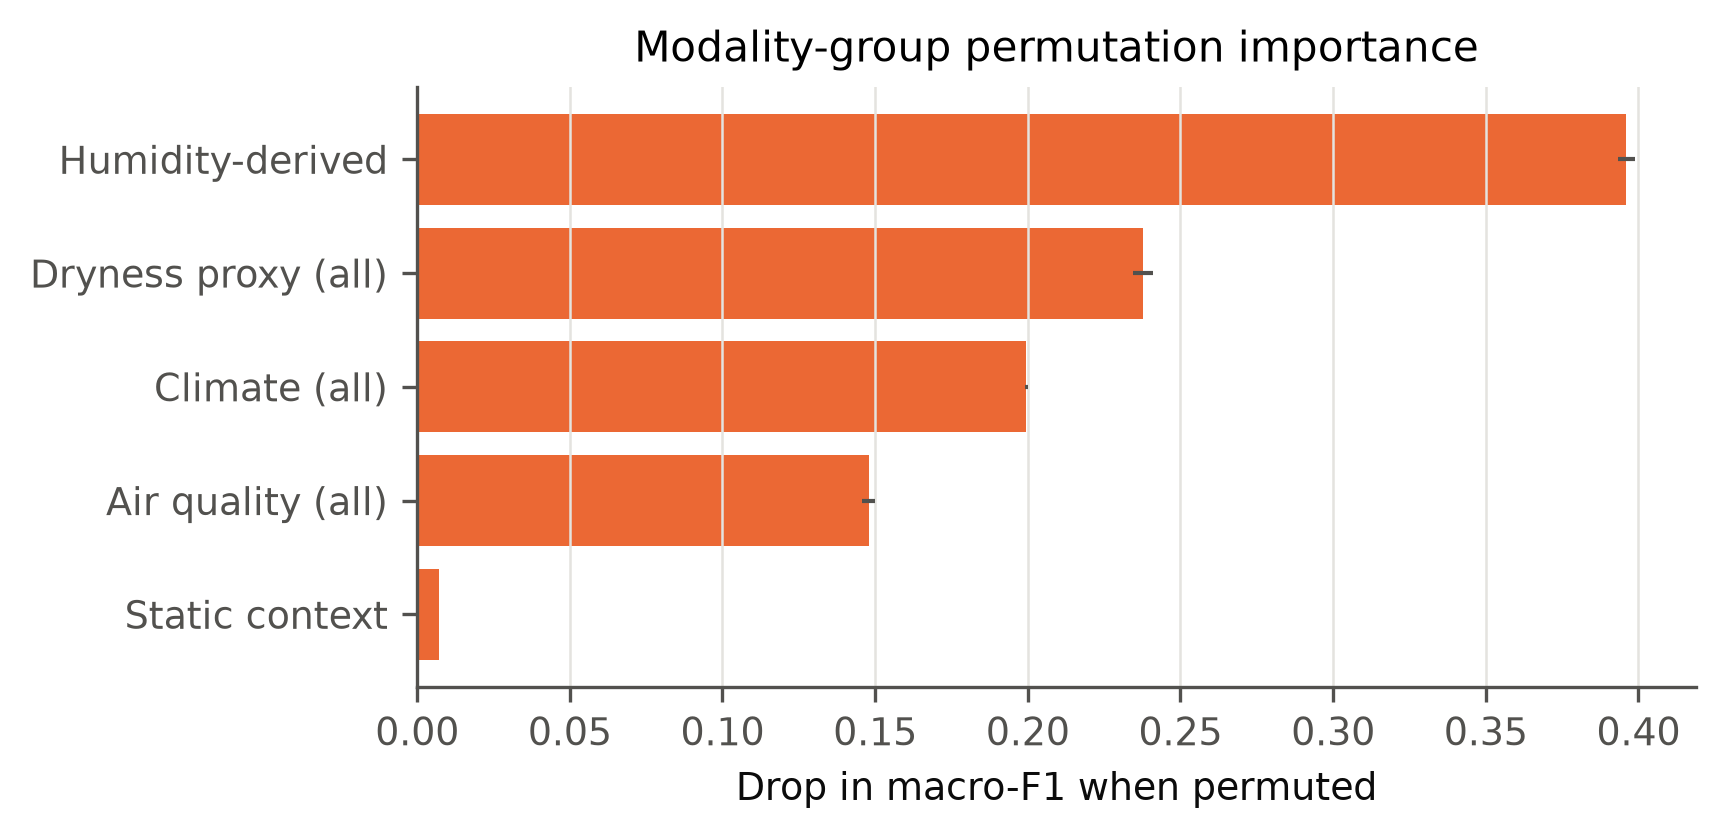

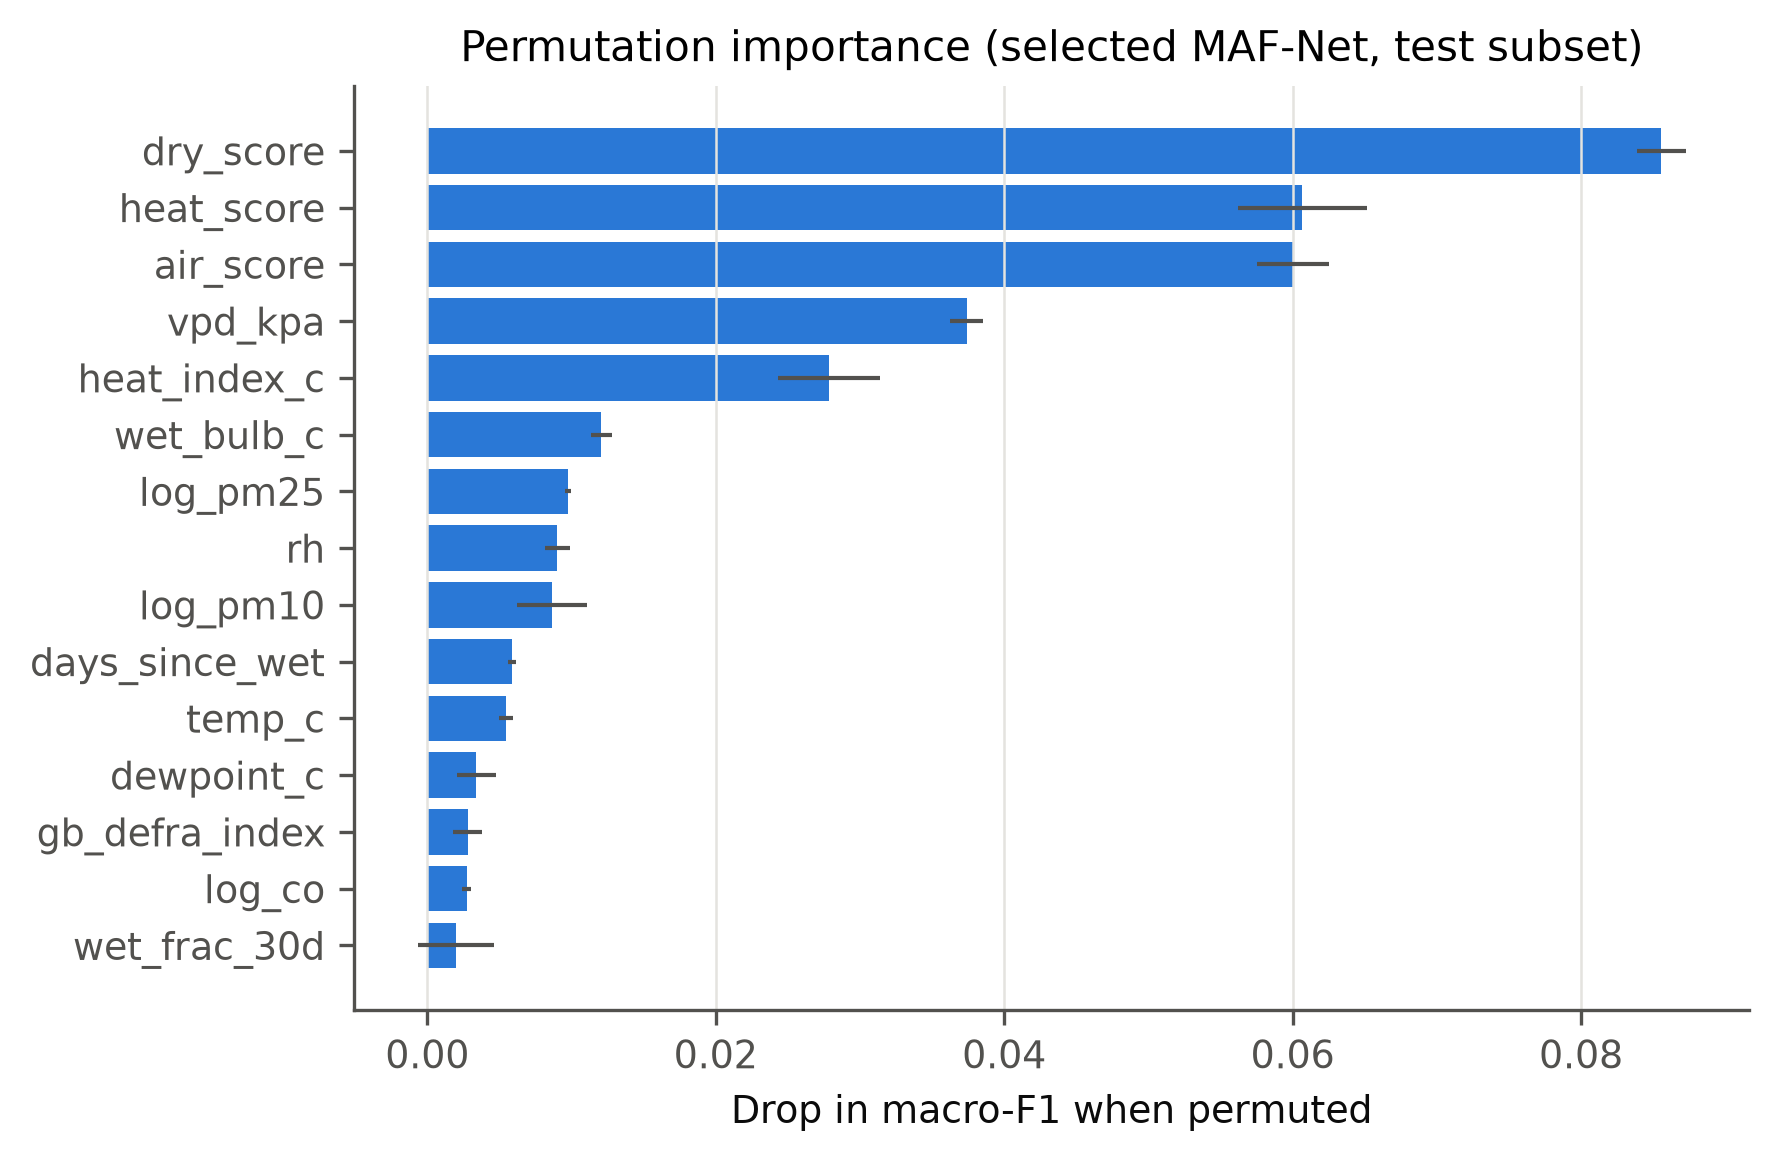

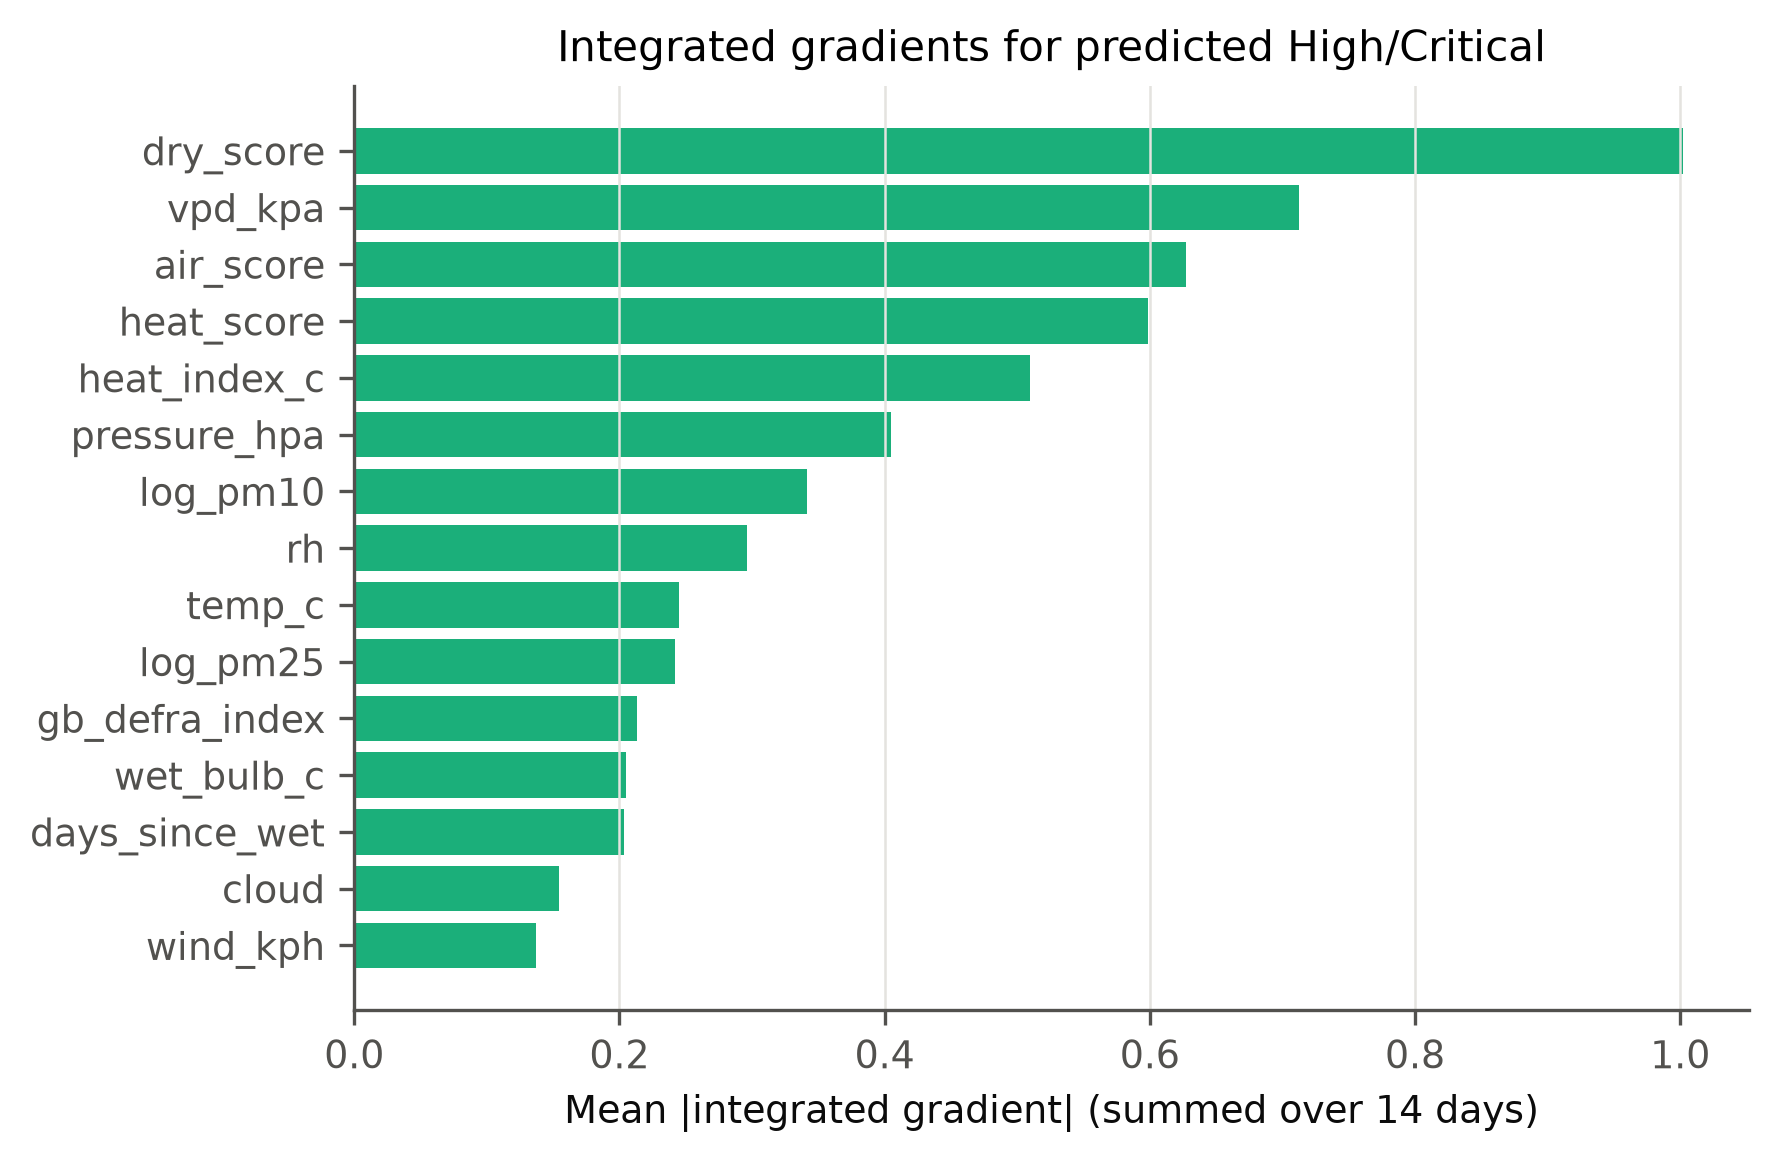

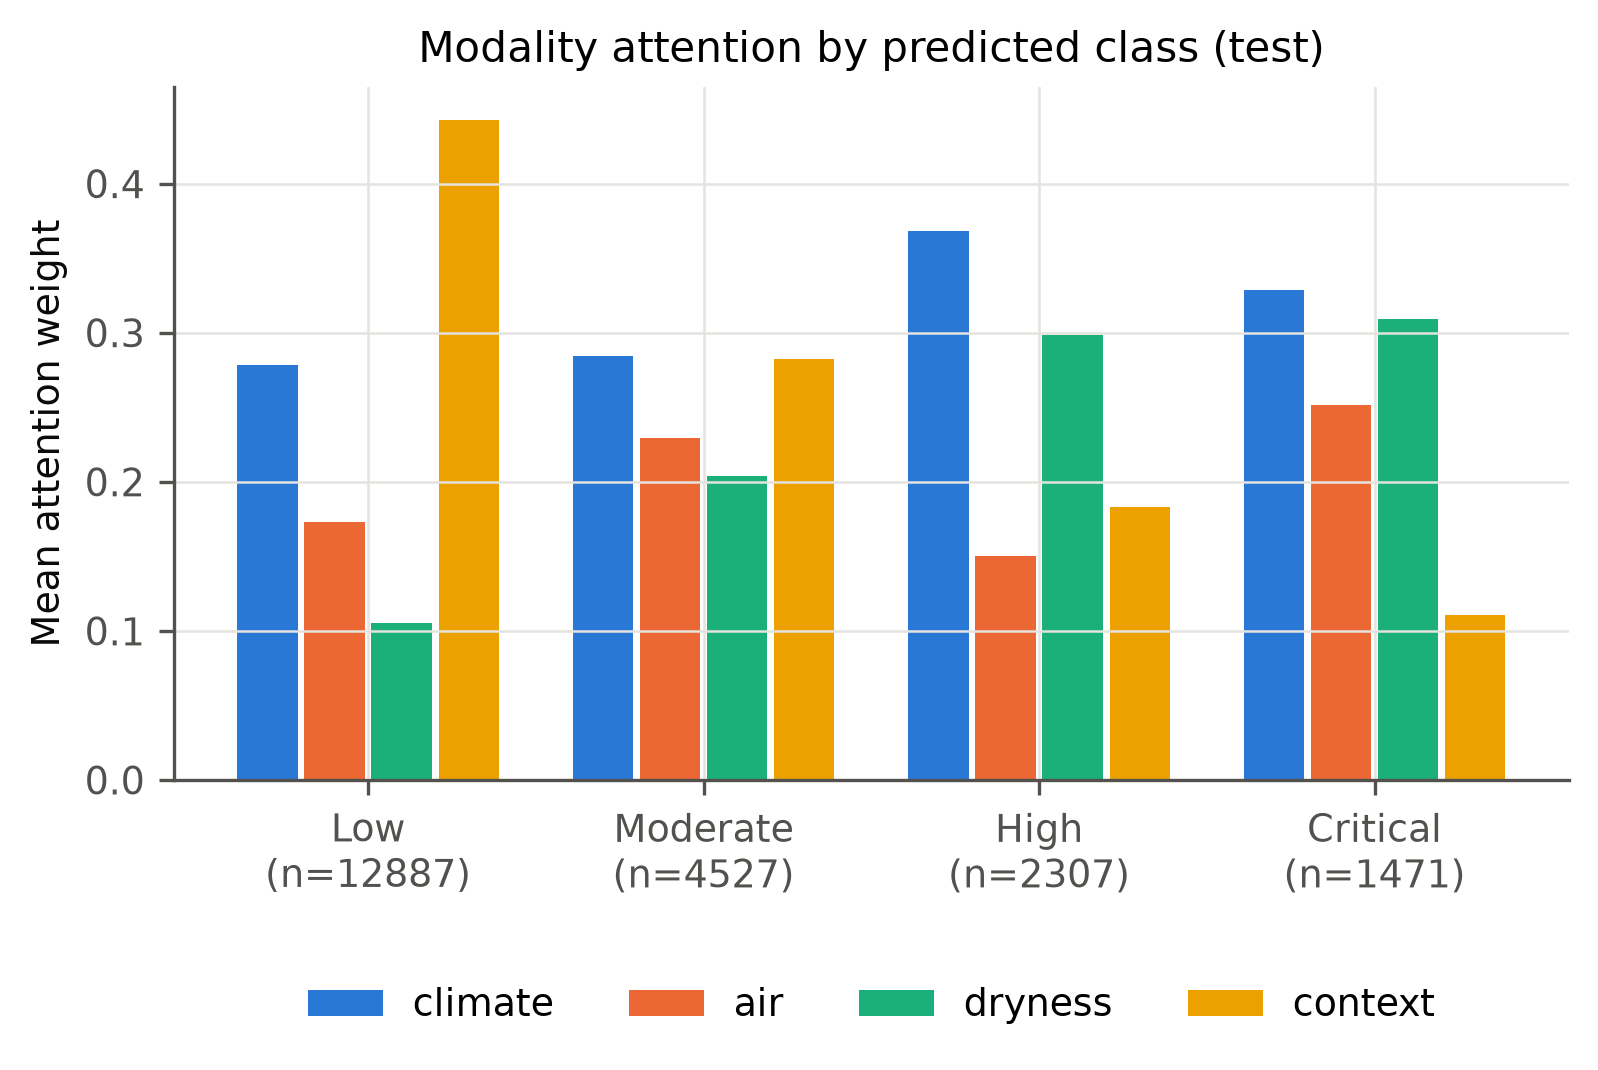

In [7]:
ex = read_json(ROOT / "results/analysis/explainability.json")
display(pd.DataFrame(ex["permutation_importance_groups"]).T.round(4))
show("results/figures/explain/permutation_importance_groups.png", 520)
show("results/figures/explain/permutation_importance_features.png", 600)
show("results/figures/explain/integrated_gradients_high_critical.png", 600)
show("results/figures/explain/attention_by_class.png", 600)

### Case studies: real held-out samples predicted High or Critical

In [8]:
cs = pd.json_normalize(ex["case_studies"])
cs[[c for c in cs.columns if not c.startswith("signals")]]

,target_date,last_input_date,city,country,actual,predicted,correct,"hazards_target_day(H,A,D)",probabilities.Low,probabilities.Moderate,probabilities.High,probabilities.Critical,attention.climate,attention.air,attention.dryness,attention.context
0,2026-09-28,2026-09-27,Jakarta,Indonesia,Critical,Critical,True,"[2, 3, 3]",0.000,0.004,0.234,0.762,0.296,0.270,0.335,0.099
1,2026-09-25,2026-09-24,Muscat,Oman,High,High,True,"[2, 1, 2]",0.001,0.065,0.561,0.373,0.416,0.113,0.326,0.145
2,2026-07-05,2026-07-04,Tehran,Iran,High,High,True,"[1, 1, 3]",0.002,0.124,0.623,0.251,0.060,0.170,0.625,0.145
3,2026-06-30,2026-06-29,Abu Dhabi,United Arab Emirates,Critical,Critical,True,"[3, 2, 3]",0.000,0.003,0.217,0.780,0.418,0.191,0.313,0.078
4,2026-10-02,2026-10-01,Dhaka,Bangladesh,Critical,High,False,"[2, 2, 2]",0.002,0.071,0.495,0.431,0.556,0.128,0.147,0.169
5,2026-08-13,2026-08-12,Baku,Azerbaijan,Moderate,High,False,"[1, 0, 2]",0.030,0.260,0.554,0.156,0.153,0.030,0.736,0.080


In [9]:
pd.DataFrame([c["signals_last_input_day"] for c in ex["case_studies"]], index=[c["city"] for c in ex["case_studies"]])

,temp_c,rh_pct,heat_index_c,pm25,pm10,o3,vpd_kpa,days_since_wet,"hazards_today(H,A,D)",class_today
Jakarta,33.5,46.0,36.1,53.4,54.9,241.0,2.79,38,"[2, 3, 3]",Critical
Muscat,32.0,55.0,35.6,22.8,78.0,49.0,2.14,60,"[2, 1, 3]",Critical
Tehran,29.1,13.0,27.4,22.2,68.5,104.0,3.51,3,"[1, 1, 3]",High
Abu Dhabi,35.1,47.0,39.8,42.6,79.2,98.0,3.00,60,"[2, 2, 3]",Critical
Dhaka,31.6,54.0,34.6,43.4,47.5,182.0,2.14,5,"[2, 2, 2]",Critical
Baku,30.8,43.0,31.1,12.2,14.9,104.0,2.53,48,"[1, 1, 3]",High


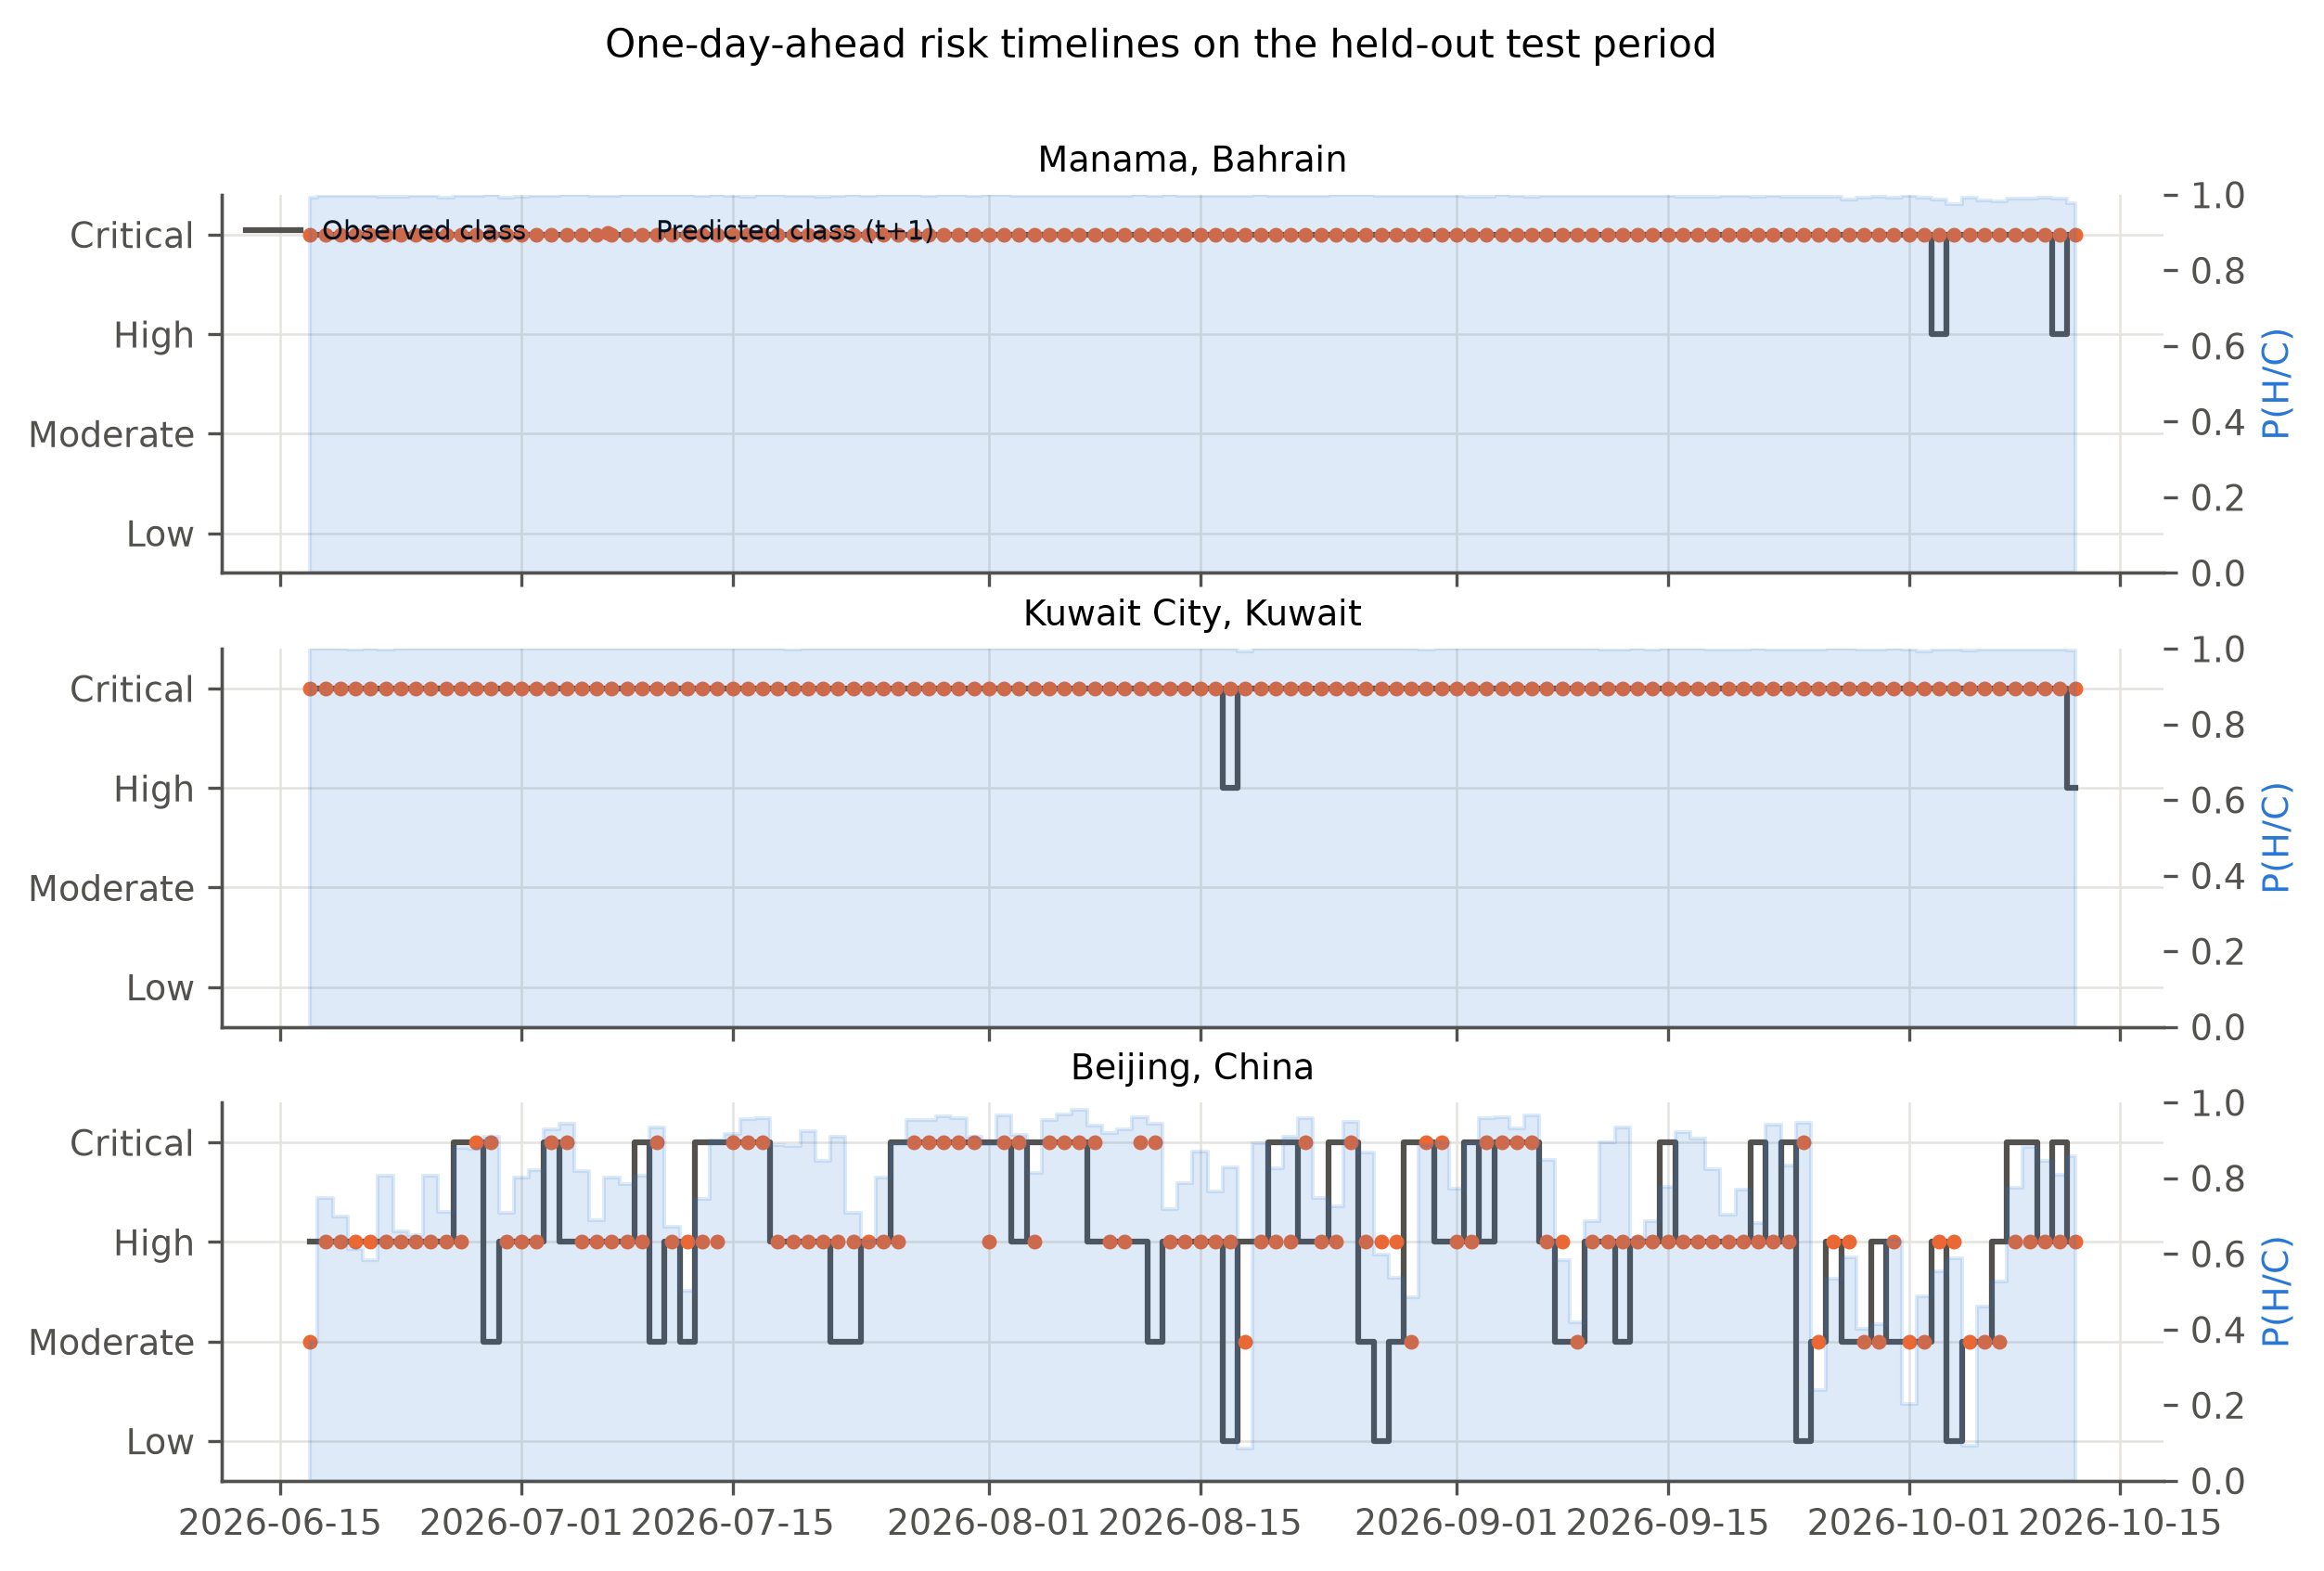

In [10]:
show("results/figures/explain/risk_timelines.png")

Predictions are model outputs for a project-defined environmental-stress class; they are not
observed human-health outcomes.

## Validity checks on frozen test predictions
**(a) Observation-hour bias.** Performance by longitude band, where the local snapshot hour differs.
**(b) Air-quality non-stationarity.** PM2.5 regimes (boundaries at the largest 7-day steps of the
cross-site median) and monthly macro-F1 across validation and test.
**(c) Label persistence.** Accuracy on days whose class is unchanged vs. days with a transition, and
recall of High/Critical *onsets* — the cases an early-warning system exists for and that
persistence can never predict.

{'spearman_hour_vs_label_all_days': 0.346654248246285, 'spearman_hour_vs_heat_score_all_days': 0.3325777442893986, 'spearman_hour_vs_predicted_class_test': 0.3691471699882326}


,band,n,sites,median_local_hour,share_high_critical,macro_f1_mafnet,macro_f1_persistence,acc_mafnet,acc_persistence
0,Americas W (<-90°),512,5,19.00,0.002,0.433,0.419,0.930,0.916
1,Americas E (-90°…-30°),3203,29,1.75,0.024,0.510,0.504,0.845,0.835
2,Europe/Africa (-30°…30°),8399,72,7.75,0.035,0.499,0.531,0.850,0.839
3,W/S Asia (30°…90°),5896,50,9.00,0.358,0.756,0.749,0.771,0.768
4,E Asia/Oceania (>90°),3182,27,14.75,0.351,0.694,0.677,0.703,0.688


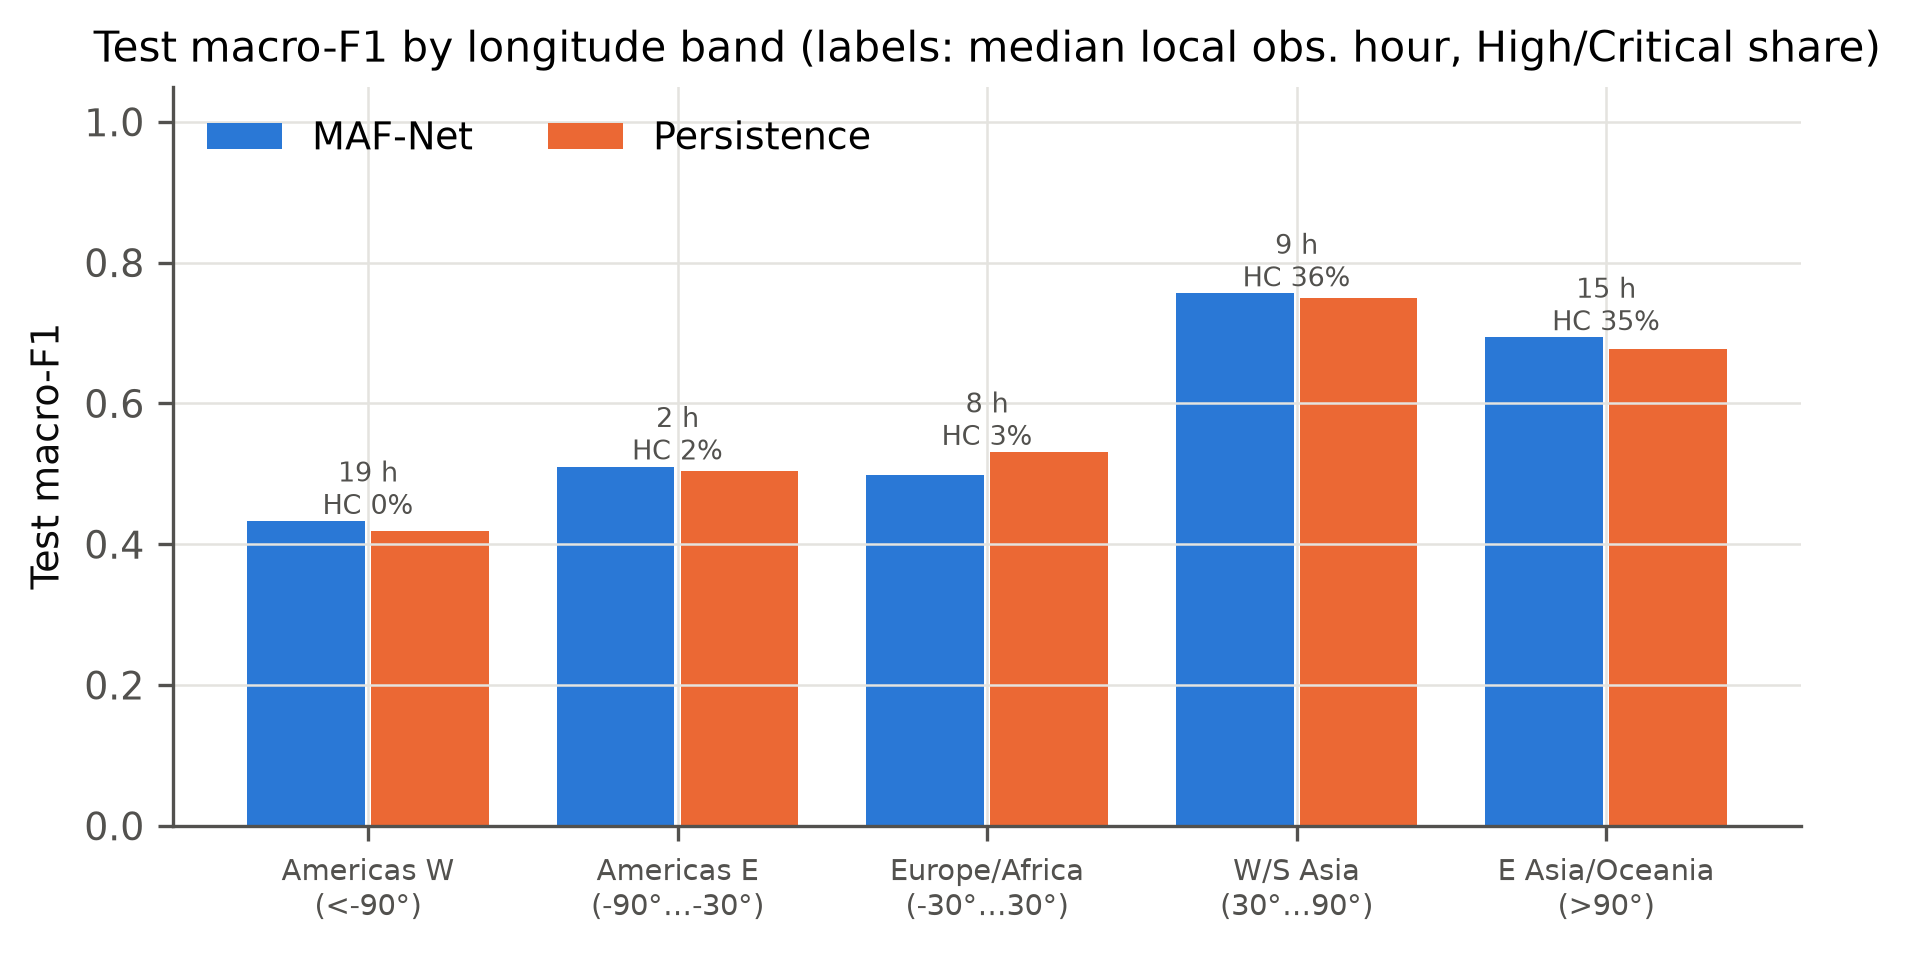

In [11]:
vc = read_json(ROOT / "results/analysis/validity_checks.json")
print(vc["obs_hour_correlation"])
display(pd.DataFrame(vc["by_longitude_band"]).round(3))
show("results/figures/validity/performance_by_longitude.png", 700)

,regime,n,median,p90,share_above_who_aqg,share_air_score_ge2
0,R1: to 2024-09-04,19674,5.10,31.500,0.225,0.128
1,R2: 2024-09-05 to 2025-09-30,72073,18.50,63.825,0.594,0.266
2,R3: from 2025-10-01,68749,11.05,39.050,0.367,0.133


KS: {'R1 vs R2': 0.4703425418351993, 'R2 vs R3': 0.23687347564164318, 'R1 vs R3': 0.3325668128083952} | training spans R1-R3 (to 2026-01-21); validation and test lie entirely in R3


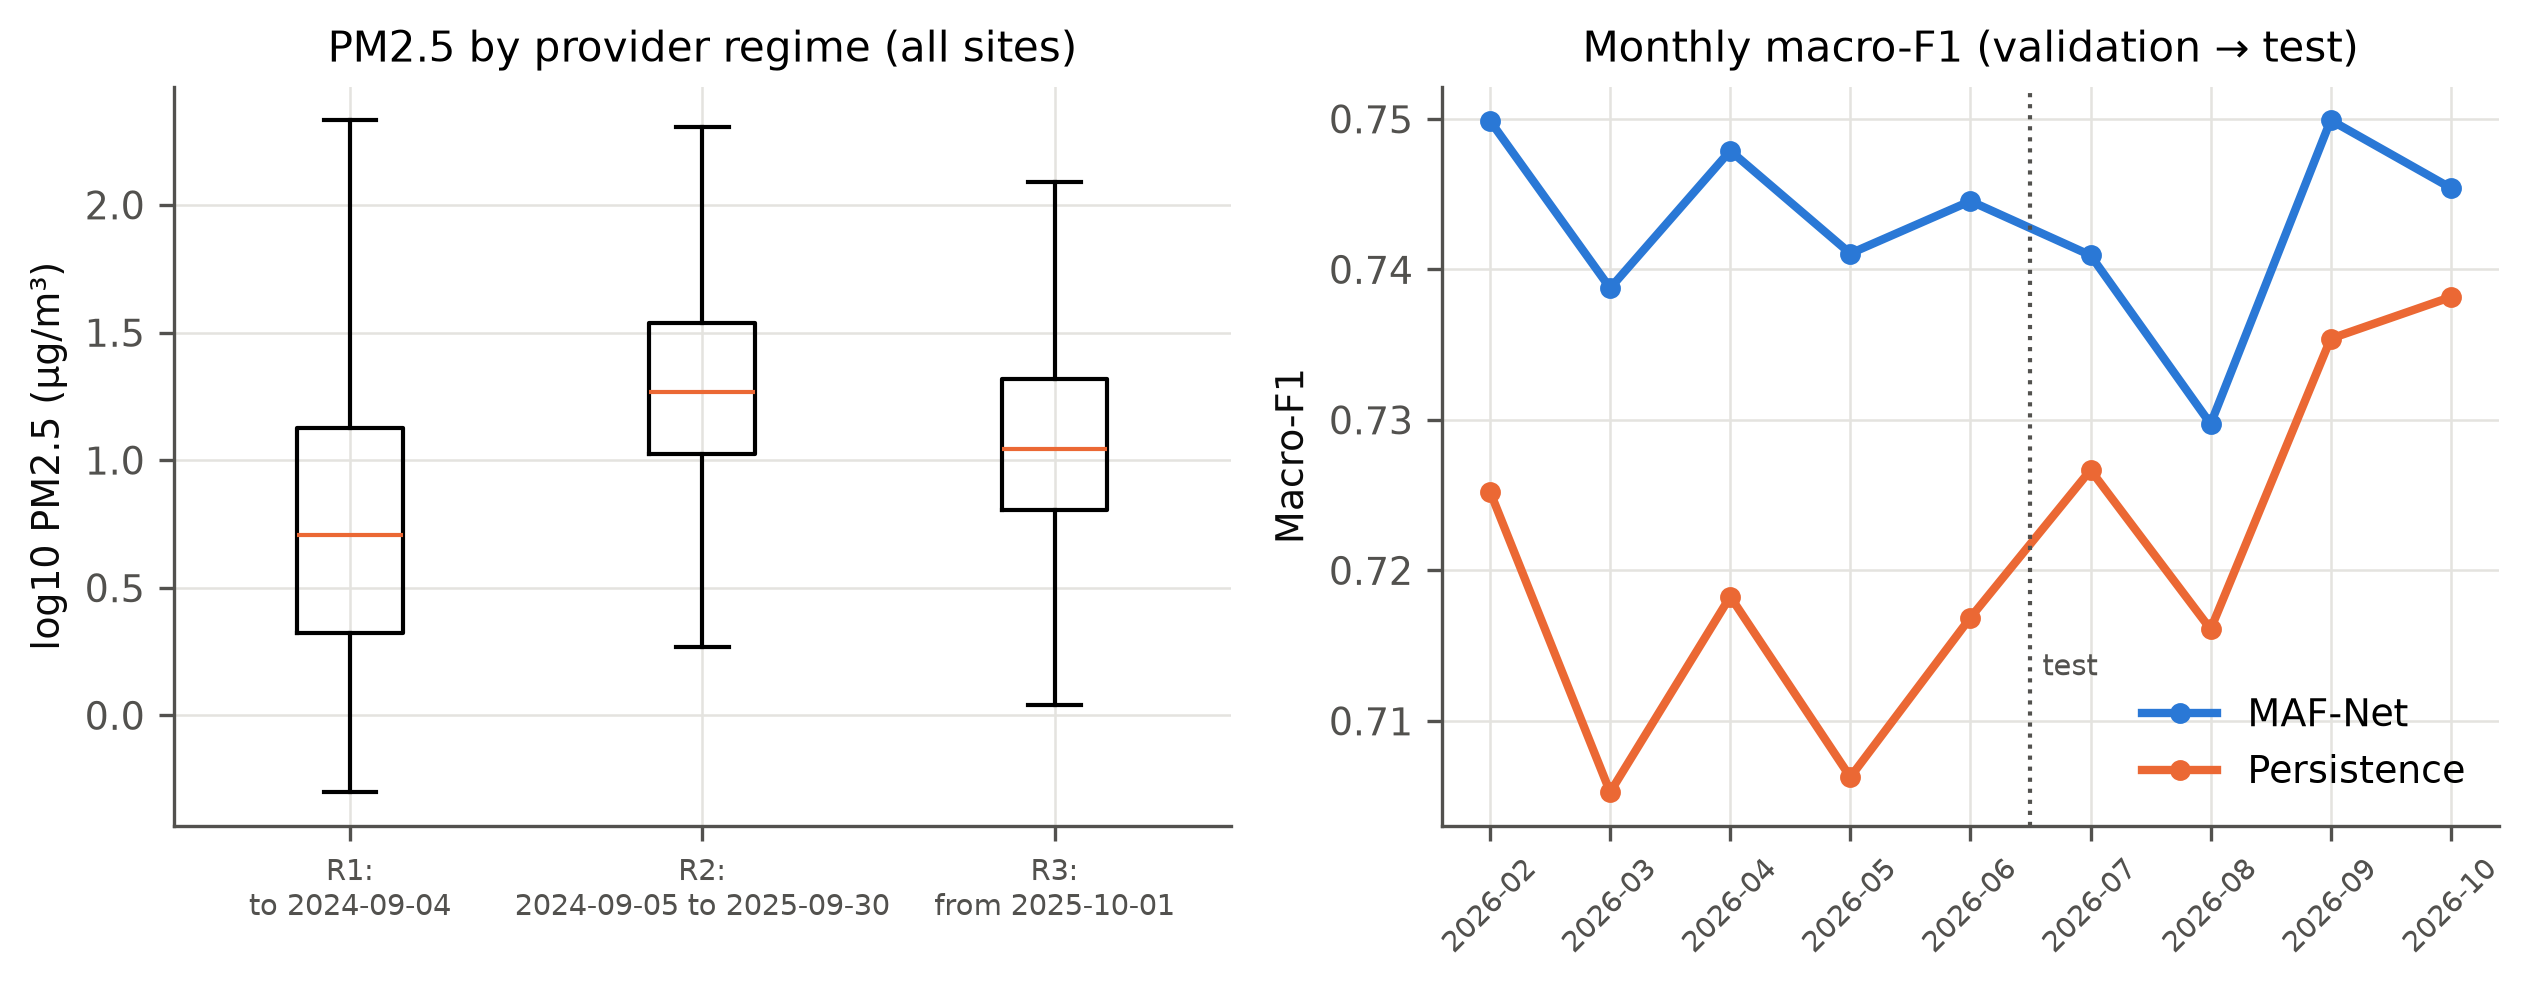

In [12]:
display(pd.DataFrame(vc["pm25_regimes"]["regimes"]).round(3)); print("KS:", vc["pm25_regimes"]["ks_statistic"], "|", vc["pm25_regimes"]["note"])
show("results/figures/validity/pm25_regimes_and_monthly_performance.png")

,subset,n,share,acc_mafnet,acc_hgb,acc_persistence
0,stable (class unchanged),16823,0.794,0.937,0.938,1.0
1,transition (class changes),4274,0.202,0.293,0.266,0.0
2,onset of High/Critical,606,0.029,0.315,0.315,0.0
3,end of High/Critical,618,0.029,0.244,0.183,0.0


test label persistence: 0.794
recall of High/Critical onsets: {'mafnet': 0.347, 'hgb': 0.351, 'persistence': 0.0}
false High/Critical alarms on stable Low/Moderate days: {'mafnet': 0.014, 'hgb': 0.014, 'persistence': 0.0}


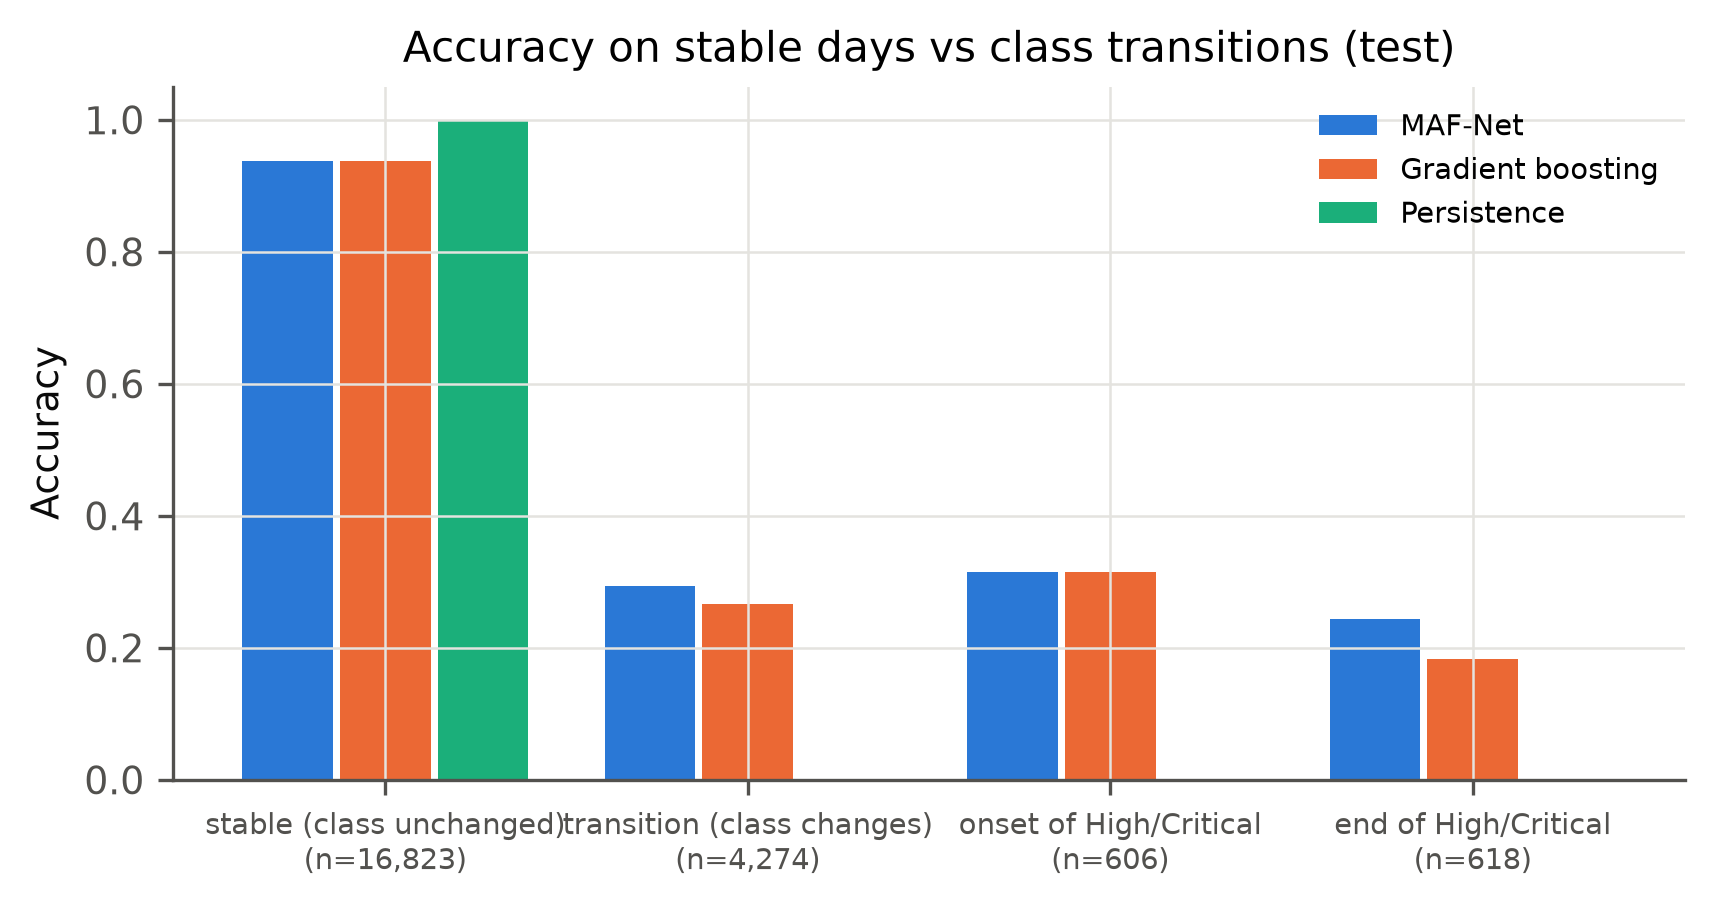

In [13]:
pa = vc["persistence_analysis"]
display(pd.DataFrame(pa["subsets"]).round(3))
print("test label persistence:", round(pa["test_label_persistence"], 3))
print("recall of High/Critical onsets:", {k: round(v, 3) for k, v in pa["onset_recall_high_or_critical"].items()})
print("false High/Critical alarms on stable Low/Moderate days:", {k: round(v, 3) for k, v in pa["false_alarm_rate_hc_on_stable_low_moderate"].items()})
show("results/figures/validity/transitions_vs_stable.png", 600)